# Circular-Structure Discovery — Gawler Craton (DEM + Magnetic)

Point this at two files and run all cells:
1. **DEM** (SRTM 1 arc-sec, ~30 m) — finds circular topographic depressions.
2. **Airborne magnetic grid** (GA SA/Gawler TMI, ~80 m) — finds circular magnetic anomalies.

It scans each over the Gawler region, **cross-matches** locations flagged by BOTH
datasets (the strong candidates), **validates** the method by checking it recovers the
known Acraman impact structure, and plots everything on a map.

This is *discovery*, not verification of old guesses: the high-resolution data itself
picks the candidates. A location circular in topography AND magnetics, that isn't a
known structure, is a genuine field-trip candidate (pending geological cross-check).

### Why this can work where the gravity approach didn't
The satellite gravity model (~25 km) was too coarse to locate craters; its candidates
all failed DEM verification. DEM (~30 m) and airborne magnetic (~80 m) are 100s of times
finer — they can actually resolve crater-sized structures.

## 0. Setup — set your two file paths here

In [9]:
DEM_PATH = "../data/raw/srtm_gawler_mosaic.tif"      # SRTM mosaic (or single .tif)
MAG_PATH = "../data/raw/Magmap2019-grid-tmi-Cellsize40m-AWAGS_MAG_2019.ers"      # GA magnetic grid (.tif or .ers); set None if not yet downloaded

# Gawler Craton region: lat0, lat1, lon0, lon1
REGION = (-34.0, -30.0, 132.0, 137.0)
ACRAMAN = (-32.0, 135.45)        # known impact structure, ~90 km -- validation target

import sys; sys.path.insert(0, "../scripts")
import numpy as np, matplotlib.pyplot as plt
from circular_scan import scan_raster, cross_match   # the tested engine
print("config loaded; region:", REGION)

config loaded; region: (-34.0, -30.0, 132.0, 137.0)


## 1. Scan the DEM for circular depressions

Tiled, windowed reads — handles large files. Radii span 2–30 km (crater range).

In [10]:
dem_cands, dem_px = scan_raster(
    DEM_PATH, mode="dem", region=REGION,
    tile_px=2000, overlap_px=200, radii_km=(2,4,8,15,25), n_final=20)
print(f"DEM resolution ~{dem_px:.0f} m/px | top depressions:")
print(f"{'rank':4s}{'score':>10s}   lat        lon")
for i,(sc,la,lo) in enumerate(dem_cands[:10],1):
    print(f"{i:4d}{sc:10.1f}   {la:8.4f}  {lo:8.4f}")

DEM resolution ~31 m/px | top depressions:
rank     score   lat        lon
   1   23507.4   -33.6689  136.9375
   2   22168.1   -33.7397  136.3200
   3   21233.0   -32.6689  135.3039
   4   19145.9   -32.2642  135.0642
   5   19106.6   -33.7744  136.6356
   6   17858.0   -32.7772  136.2533
   7   17256.8   -32.6736  135.8050
   8   17254.7   -32.4356  135.5739
   9   16306.8   -33.5000  136.6589
  10   16244.9   -32.1094  135.3472


## 2. Scan the magnetic grid for circular anomalies

In [11]:
if MAG_PATH:
    mag_cands, mag_px = scan_raster(
        MAG_PATH, mode="mag", region=REGION,
        tile_px=2000, overlap_px=200, radii_km=(2,4,8,15,25), n_final=20)
    print(f"MAG resolution ~{mag_px:.0f} m/px | top anomalies:")
    for i,(sc,la,lo) in enumerate(mag_cands[:10],1):
        print(f"{i:4d}{sc:10.1f}   {la:8.4f}  {lo:8.4f}")
else:
    mag_cands = []
    print("No magnetic file set -- running DEM-only. Cross-match will be skipped.")

MAG resolution ~44 m/px | top anomalies:
   1  194729.9   -30.6670  136.6730
   2  181700.1   -30.8930  132.6126
   3  178309.7   -30.5330  136.9054
   4  156215.8   -30.2966  136.6938
   5  119293.7   -30.6446  134.5674
   6  117180.7   -30.3190  134.7742
   7  116798.3   -33.0874  135.6326
   8  107491.2   -30.0238  135.1054
   9  104818.2   -30.6566  132.8018
  10   95053.4   -32.9626  134.9718


## 3. Validate the method against Acraman

Before trusting any *new* candidate, confirm the scanner finds a *known* 90 km crater.
If Acraman ranks well, the method works on real data. If not, adjust radii/parameters
before drawing conclusions.

In [12]:
def nearest(cands, lat, lon):
    if not cands: return None
    d = [(np.hypot(la-lat, lo-lon), r+1, sc, la, lo)
         for r,(sc,la,lo) in enumerate(cands)]
    d.sort(); return d[0]

for label, cands in [("DEM", dem_cands), ("MAG", mag_cands)]:
    n = nearest(cands, *ACRAMAN)
    if n is None:
        print(f"{label}: no candidates"); continue
    dist, rank, sc, la, lo = n
    dkm = dist*111
    verdict = "FOUND (method validated)" if dkm < 30 else "not in top list (check params)"
    print(f"{label}: nearest to Acraman is rank {rank}, {dkm:.0f} km away, score {sc:.0f} -> {verdict}")

DEM: nearest to Acraman is rank 14, 11 km away, score 14152 -> FOUND (method validated)
MAG: nearest to Acraman is rank 10, 119 km away, score 95053 -> not in top list (check params)


## 4. Cross-match — candidates in BOTH datasets (the strong ones)

In [13]:
if dem_cands and mag_cands:
    matched = cross_match(dem_cands, mag_cands, tol_deg=0.15, top=15)
    print(f"{len(matched)} locations flagged by BOTH DEM and magnetic:")
    print(f"{'lat':>9s}{'lon':>9s}{'dem':>10s}{'mag':>10s}   near_known?")
    KNOWN = {"Acraman":ACRAMAN}
    for m in matched:
        nk = min(((np.hypot(m['lat']-v[0], m['lon']-v[1])*111, k)
                  for k,v in KNOWN.items()), default=(999,""))
        tag = f"{nk[1]} ({nk[0]:.0f}km)" if nk[0]<40 else "NEW"
        print(f"{m['lat']:9.3f}{m['lon']:9.3f}{m['dem_score']:10.0f}{m['mag_score']:10.0f}   {tag}")
else:
    matched = []
    print("Need both DEM and magnetic scans for cross-match.")

2 locations flagged by BOTH DEM and magnetic:
      lat      lon       dem       mag   near_known?
  -33.727  136.681     19107     79733   NEW
  -32.996  134.956     13239     95053   NEW


## 5. Map the candidates

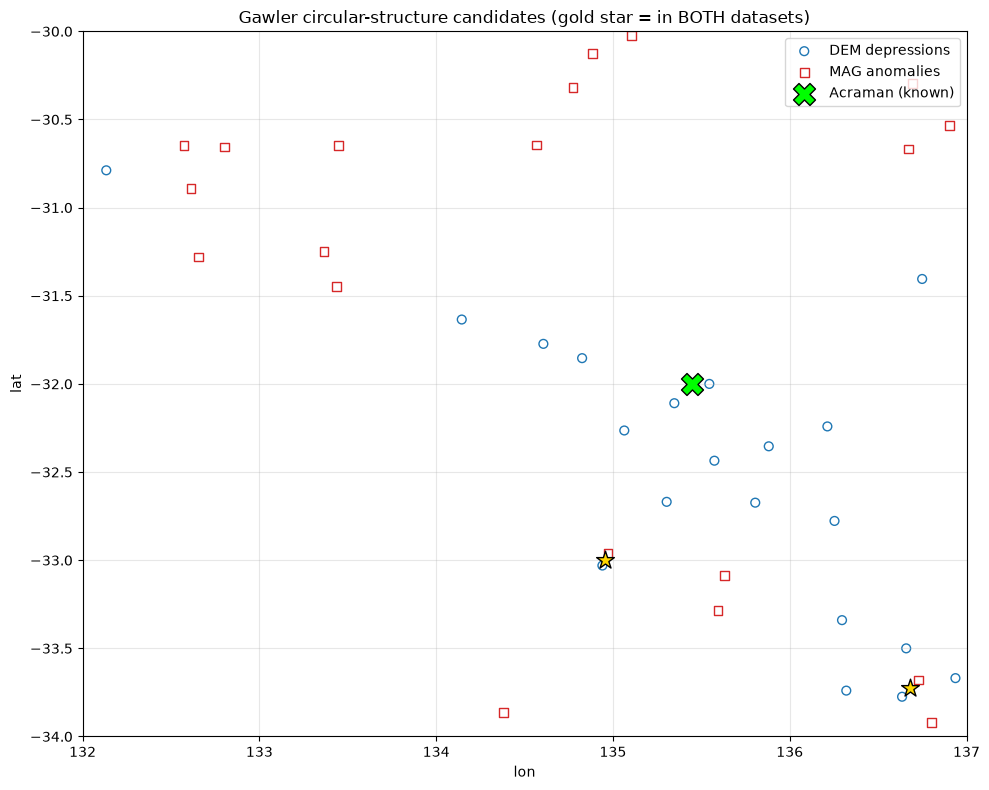

In [14]:
fig, ax = plt.subplots(figsize=(10,8))
lat0,lat1,lon0,lon1 = REGION
ax.set_xlim(lon0,lon1); ax.set_ylim(lat0,lat1)
if dem_cands:
    d=np.array([(lo,la,sc) for sc,la,lo in dem_cands])
    ax.scatter(d[:,0],d[:,1],s=40,facecolors="none",edgecolors="tab:blue",label="DEM depressions")
if mag_cands:
    m=np.array([(lo,la,sc) for sc,la,lo in mag_cands])
    ax.scatter(m[:,0],m[:,1],s=40,marker="s",facecolors="none",edgecolors="tab:red",label="MAG anomalies")
for mm in matched:
    ax.scatter(mm["lon"],mm["lat"],s=180,marker="*",color="gold",
               edgecolors="k",zorder=5,label="_match")
ax.scatter(*ACRAMAN[::-1],s=250,marker="X",color="lime",edgecolors="k",
           zorder=6,label="Acraman (known)")
ax.set_xlabel("lon"); ax.set_ylabel("lat")
ax.set_title("Gawler circular-structure candidates (gold star = in BOTH datasets)")
ax.legend(loc="upper right"); ax.grid(alpha=0.3); plt.tight_layout(); plt.show()

In [15]:
import rasterio
with rasterio.open(MAG_PATH) as ds:
    print("CRS:", ds.crs)
    print("bounds:", ds.bounds)
    print("nodata:", ds.nodata)

CRS: GEOGCS["GEOCENTRIC DATUM of AUSTRALIA",DATUM["GDA94",SPHEROID["GRS80",6378137,298.257222101]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433],AXIS["Longitude",EAST],AXIS["Latitude",NORTH]]
bounds: BoundingBox(left=132.5456, bottom=-34.8648, right=137.5532, top=-29.1584)
nodata: -99999.0


## 6. Next steps for any strong candidate

For each gold-star (cross-matched) candidate that is NOT a known structure:
1. Load its DEM tile in QGIS, add a **hillshade** (and MultidirectionalHillshade) — look
   for a closed circular rim + central depression/peak. Erosional/linear = reject.
2. Overlay the **SA geological map** — rule out granite plutons, volcanic centres,
   salt structures (all can be circular in both datasets).
3. Confirm it is not in the Earth Impact Database or known mineral-deposit catalogues.
4. A circular structure in topography AND magnetics, geologically unexplained and
   uncatalogued, is what justifies a field trip.

**Honest caveat:** most circular features will still be non-impact (calderas, diatremes,
salt domes). This method finds *real circular structures to evaluate*, not confirmed
craters. Confirmation needs field evidence (shatter cones, shocked quartz).